In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster


In [2]:
df = pd.read_csv("Admission_Prediction_TimeSeries_Ready.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())

Dataset shape: (1000, 12)

Column names:
['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit', 'Application_DateTime', 'University_Name', 'region']

First five records:


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
0,1,337,118,4,4.5,4.5,9.65,1,0.92,2022-01-01 09:00:00,Indian Institute of Technology Kharagpur,East
1,2,324,107,4,4.0,4.5,8.87,1,0.76,2022-01-02 09:00:00,National Institute of Technology Karnataka,South
2,3,316,104,3,3.0,3.5,8.00,1,0.72,2022-01-04 09:00:00,Gujarat University,West
3,4,322,110,3,3.5,2.5,8.67,1,0.80,2022-01-06 09:00:00,Jamia Millia Islamia,North
4,5,314,103,2,2.0,3.0,8.21,0,0.65,2022-01-08 09:00:00,Jamia Millia Islamia,North


In [3]:
# Check missing values, data types, duplicates, and numerical summaries.
print("Data types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing values per column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nNumerical summary:")
display(df.describe().T)

Data types:


,Data Type
Serial No.,int64
GRE Score,int64
TOEFL Score,int64
University Rating,int64
SOP,float64
LOR,float64
CGPA,float64
Research,int64
Chance of Admit,float64
Application_DateTime,object



Missing values per column:


,Missing Values
Serial No.,0
GRE Score,0
TOEFL Score,0
University Rating,0
SOP,0
LOR,0
CGPA,0
Research,0
Chance of Admit,0
Application_DateTime,0



Duplicate rows: 0

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
Serial No.,1000.0,500.50000,288.819436,1.00,250.7500,500.50,750.25,1000.00
GRE Score,1000.0,315.96500,13.415653,290.00,305.0000,316.00,326.25,340.00
TOEFL Score,1000.0,106.56400,7.634277,92.00,101.0000,107.00,113.00,120.00
University Rating,1000.0,3.01500,1.317768,1.00,2.0000,3.00,4.00,5.00
SOP,1000.0,3.39350,1.027279,0.90,2.5000,3.50,4.00,5.10
LOR,1000.0,3.40670,0.891864,0.90,3.0000,3.50,4.00,5.10
CGPA,1000.0,8.58979,0.612170,6.77,8.1800,8.58,9.07,9.95
Research,1000.0,0.50300,0.500241,0.00,0.0000,1.00,1.00,1.00
Chance of Admit,1000.0,0.71777,0.145910,0.32,0.6375,0.72,0.82,0.97


In [4]:
# Select commonly used applicant profile features when they exist.
candidate_features = [
    "GRE Score",
    "TOEFL Score",
    "University Rating",
    "SOP",
    "LOR",
    "CGPA",
    "Research"
]

feature_columns = [col for col in candidate_features if col in df.columns]

if len(feature_columns) < 2:
    raise ValueError(
        "Fewer than two expected numerical applicant features were found. "
        "Review df.columns and update candidate_features."
    )

print("Features used for clustering:")
print(feature_columns)

# Convert selected features to numeric; invalid entries become missing values.
X_raw = df[feature_columns].apply(pd.to_numeric, errors="coerce")

# Drop columns that have no usable values.
X_raw = X_raw.dropna(axis=1, how="all")
feature_columns = X_raw.columns.tolist()

print("\nFeatures retained after removing entirely missing columns:")
print(feature_columns)

Features used for clustering:
['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']

Features retained after removing entirely missing columns:
['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']


In [5]:
# Replace infinite values with NaN before imputing.
X_raw = X_raw.replace([np.inf, -np.inf], np.nan)

# Fill missing feature values with each column's median.
# Median imputation is less sensitive to extreme values than mean imputation.
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_raw)

# Standardize features so larger-scale variables do not dominate distances.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("Prepared matrix shape:", X_scaled.shape)
print("Number of applicants:", X_scaled.shape[0])
print("Number of features:", X_scaled.shape[1])

Prepared matrix shape: (1000, 7)
Number of applicants: 1000
Number of features: 7


In [6]:
# Ward linkage merges clusters while aiming to minimize the increase
# in within-cluster variance. Euclidean distance is used with Ward linkage.
# Dendrograms become difficult to read with thousands of records.
# For large datasets, use a reproducible sample for visualization.
max_rows_for_dendrogram = 500
rng = np.random.default_rng(42)

if X_scaled.shape[0] > max_rows_for_dendrogram:
    sample_indices = np.sort(
        rng.choice(
            X_scaled.shape[0],
            size=max_rows_for_dendrogram,
            replace=False
        )
    )
    X_for_tree = X_scaled[sample_indices]
    print(f"Using a reproducible sample of {max_rows_for_dendrogram} applicants for the dendrogram.")
else:
    sample_indices = np.arange(X_scaled.shape[0])
    X_for_tree = X_scaled
    print("Using all applicants for the dendrogram.")

# Create the hierarchical linkage matrix.
Z = linkage(X_for_tree, method="ward", metric="euclidean")

print("Linkage matrix shape:", Z.shape)

Using a reproducible sample of 500 applicants for the dendrogram.
Linkage matrix shape: (499, 4)


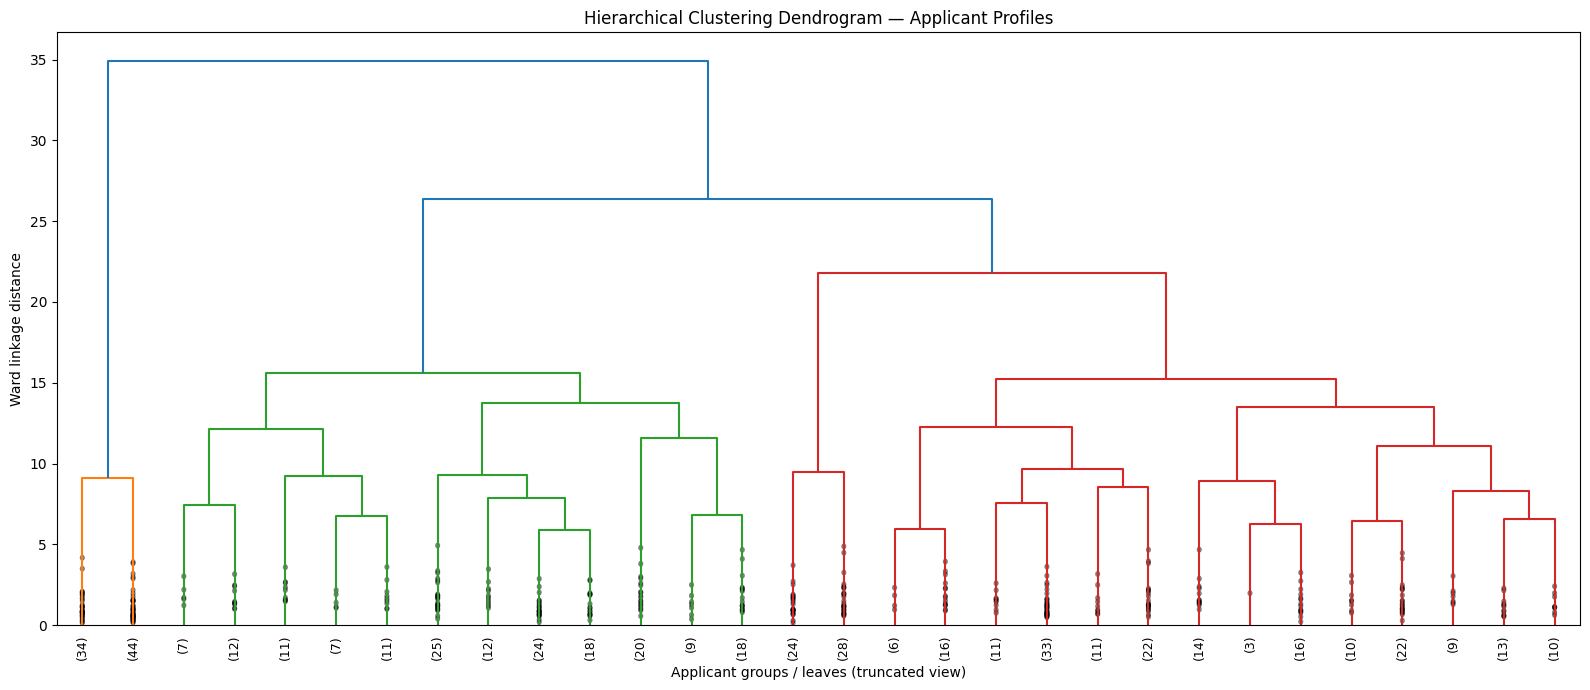

In [10]:
# Each leaf represents one applicant in the sample.
# The height where branches join represents the distance at which clusters merge.
plt.figure(figsize=(16, 7))

dendrogram(
    Z,
    truncate_mode="lastp",  
    p=30,                  
    leaf_rotation=90,
    leaf_font_size=9,
    show_contracted=True
)

plt.title("Hierarchical Clustering Dendrogram — Applicant Profiles")
plt.xlabel("Applicant groups / leaves (truncated view)")
plt.ylabel("Ward linkage distance")
plt.tight_layout()
plt.show()

In [11]:
# Select a tentative cluster count to explore segmentation.
# Try values such as 2, 3, 4, or 5 and compare the resulting profiles.
n_clusters = 3

if X_scaled.shape[0] < n_clusters:
    raise ValueError("The number of clusters cannot exceed the number of applicants.")

# Fit hierarchical clustering to all prepared applicant records.
# This is separate from the sample used only to display the dendrogram.
cluster_model = AgglomerativeClustering(
    n_clusters=n_clusters,
    linkage="ward"
)

cluster_labels = cluster_model.fit_predict(X_scaled)

# Attach cluster labels to a copy of the original dataset.
clustered_df = df.copy()
clustered_df["Applicant Cluster"] = cluster_labels + 1  # Label clusters 1, 2, 3...

print("Applicants per cluster:")
display(clustered_df["Applicant Cluster"].value_counts().sort_index().to_frame("Applicant Count"))

Applicants per cluster:


,Applicant Count
Applicant Cluster,
1,538
2,322
3,140


Average applicant feature values by cluster:


,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research
Applicant Cluster,,,,,,,
1,312.64,105.30,2.70,3.21,3.31,8.49,0.08
2,316.30,105.55,2.90,3.27,3.24,8.51,1.00
3,327.97,113.74,4.49,4.39,4.16,9.16,0.99


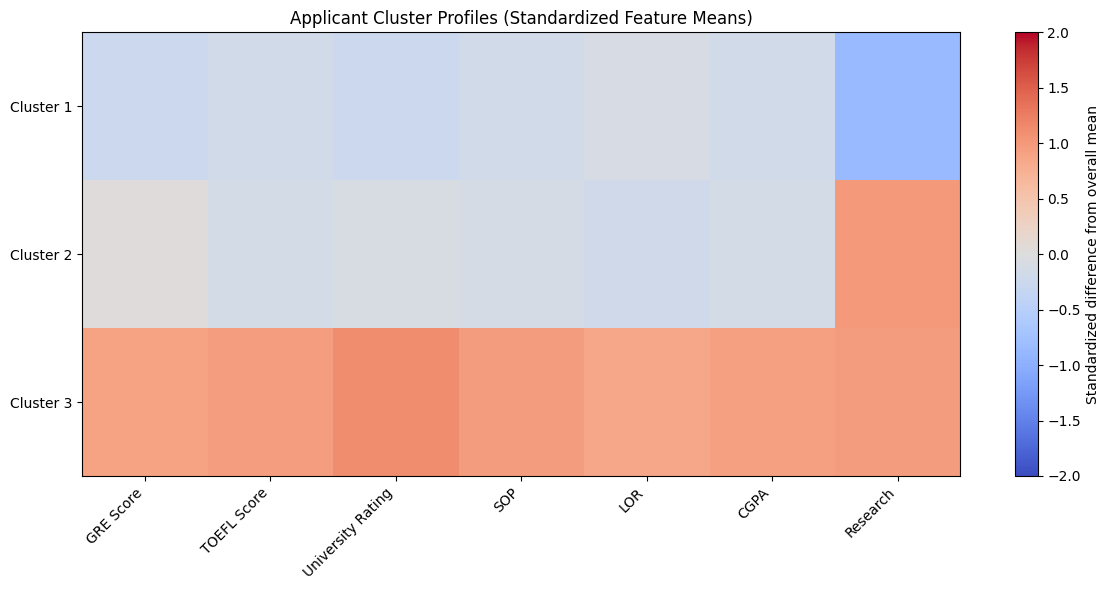

In [12]:
# Summarize average feature values by cluster to understand each segment.
profile_features = [
    col for col in feature_columns if col in clustered_df.columns
]

cluster_profiles = clustered_df.groupby("Applicant Cluster")[profile_features].mean()

print("Average applicant feature values by cluster:")
display(cluster_profiles.round(2))

# Plot the profiles after standardizing the cluster means for easier comparison.
# Positive values mean above the overall average; negative values mean below it.
overall_mean = X_raw[profile_features].mean()
overall_std = X_raw[profile_features].std().replace(0, np.nan)
standardized_profiles = (cluster_profiles - overall_mean) / overall_std

plt.figure(figsize=(12, 6))
plt.imshow(standardized_profiles, aspect="auto", cmap="coolwarm", vmin=-2, vmax=2)
plt.colorbar(label="Standardized difference from overall mean")
plt.xticks(
    ticks=np.arange(len(profile_features)),
    labels=profile_features,
    rotation=45,
    ha="right"
)
plt.yticks(
    ticks=np.arange(len(standardized_profiles.index)),
    labels=[f"Cluster {c}" for c in standardized_profiles.index]
)
plt.title("Applicant Cluster Profiles (Standardized Feature Means)")
plt.tight_layout()
plt.show()

Admission chance summary by applicant cluster:


,count,mean,median,std
Applicant Cluster,,,,
1,538,0.682,0.69,0.137
2,322,0.722,0.73,0.141
3,140,0.845,0.88,0.116


<Figure size 900x500 with 0 Axes>

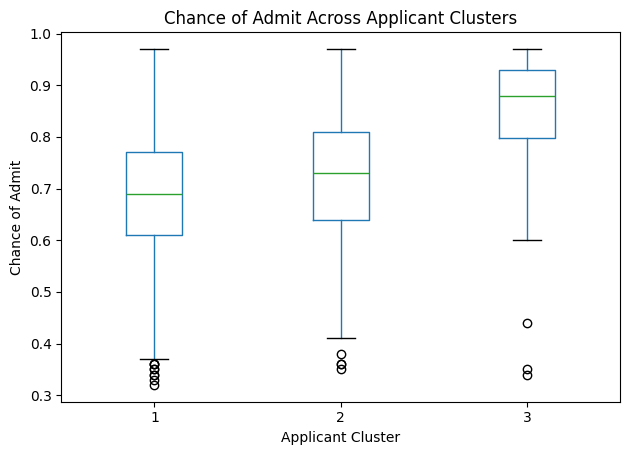

In [13]:
# Chance of Admit is useful for describing discovered clusters,
# but it is excluded from the clustering features above.
# If you decide to include it as a clustering feature, the groups will partly
# reflect the target itself, which may not be appropriate for segmentation.
if "Chance of Admit" in clustered_df.columns:
    print("Admission chance summary by applicant cluster:")
    display(
        clustered_df.groupby("Applicant Cluster")["Chance of Admit"]
        .agg(["count", "mean", "median", "std"])
        .round(3)
    )

    plt.figure(figsize=(9, 5))
    clustered_df.boxplot(
        column="Chance of Admit",
        by="Applicant Cluster",
        grid=False
    )
    plt.title("Chance of Admit Across Applicant Clusters")
    plt.suptitle("")
    plt.xlabel("Applicant Cluster")
    plt.ylabel("Chance of Admit")
    plt.tight_layout()
    plt.show()
else:
    print("Chance of Admit column not found; skipping this comparison.")